In [5]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
import sys

# Set aesthetic preferences
sns.set_theme(style="whitegrid", palette="viridis")

In [6]:
# ==========================================
# 1. LOAD EBSD DATA & PARSE HEADERS (Your Source)
# ==========================================
file_path = "ebsd.txt"
print(f"Loading EBSD data from {file_path}...")

try:
    with open(file_path, 'r') as file:
        lines = file.readlines()

    # --- Parse Header for Grid Dimensions (NROWS, etc.) ---
    header_info = {
        line.split(":")[0].strip().replace('# ', ''): line.split(":")[1].strip() 
        for line in lines 
        if line.startswith("# ") and ":" in line and not line.startswith('# COLUMN')
    }
    
    # We need these for the Zig-Zag mapping later
    NCOLS_ODD = int(header_info.get('NCOLS_ODD', 0))
    NCOLS_EVEN = int(header_info.get('NCOLS_EVEN', 0))
    NROWS = int(header_info.get('NROWS', 20)) # Default to 20 if not found, but it should be there
    
    print(f"Header Info: NROWS={NROWS}, NCOLS_ODD={NCOLS_ODD}, NCOLS_EVEN={NCOLS_EVEN}")

    # --- Find Data Start ---
    header_end_index = None
    column_headers_line = None
    for i, line in enumerate(lines):
        if line.strip() == "# HEADER: End":
            header_end_index = i
        if line.startswith("# COLUMN_HEADERS:"):
            column_headers_line = line

    if header_end_index is None or column_headers_line is None:
        raise ValueError("Could not find required header information.")

    # Parse Column Headers
    column_headers = column_headers_line.split(":")[1].strip().split(",")
    column_headers = [header.strip() for header in column_headers]

    # Load Data
    data_string = "".join(lines[header_end_index+1:])
    df_ebsd = pd.read_csv(io.StringIO(data_string), sep='\s+', names=column_headers)
    print(f"EBSD Data loaded successfully: {len(df_ebsd)} points.")

except Exception as e:
    print(f"Error loading EBSD: {e}")
    sys.exit()


Loading EBSD data from ebsd.txt...
Header Info: NROWS=203, NCOLS_ODD=418, NCOLS_EVEN=417
EBSD Data loaded successfully: 84753 points.


In [7]:
# ==========================================
# 2. DBSCAN CLUSTERING (Your Source)
# ==========================================
print("\n--- Starting Clustering Process ---")

# Isolate points belonging to indents (using IQ/CI filter)
# Using 'x' and 'y' (lowercase) as per your second snippet's headers
indent_points_df_initial = df_ebsd[(df_ebsd['CI'] <= 0.1) | (df_ebsd['IQ'] <= 100)].copy()

# Apply Bounding Box Filter
x_min_boundary = -5   
x_max_boundary = 325  
y_min_boundary = -5   
y_max_boundary = 115  

indent_points_df_filtered = indent_points_df_initial[
    (indent_points_df_initial['x'] > x_min_boundary) & 
    (indent_points_df_initial['x'] < x_max_boundary) &
    (indent_points_df_initial['y'] > y_min_boundary) & 
    (indent_points_df_initial['y'] < y_max_boundary)
].copy()

print(f"Points after bounding box filter: {len(indent_points_df_filtered)}")

# Run DBSCAN
coordinates = indent_points_df_filtered[['x', 'y']]
db = DBSCAN(eps=1.5, min_samples=3).fit(coordinates)
indent_points_df_filtered['cluster_label'] = db.labels_

# Calculate Centers
clusters_df = indent_points_df_filtered[indent_points_df_filtered['cluster_label'] != -1]
indent_centers = clusters_df.groupby('cluster_label')[['x', 'y']].mean().reset_index()
print(f"Successfully identified {len(indent_centers)} indent centers.")



--- Starting Clustering Process ---
Points after bounding box filter: 8480
Successfully identified 1000 indent centers.


In [8]:
# ==========================================
# 3. ZIG-ZAG MAPPING & OFFSET
# ==========================================
print("\n--- Applying Zig-Zag Mapping ---")

# A. IDENTIFY ROWS (Sort by Y)
# We use KMeans to robustly group the Y-coordinates into 'NROWS' clusters
kmeans_rows = KMeans(n_clusters=NROWS, n_init=10, random_state=42).fit(indent_centers[['y']])
indent_centers['row_label_raw'] = kmeans_rows.labels_

# Map the arbitrary KMeans labels to actual physical order (0=Bottom, N=Top)
row_centers_mean = indent_centers.groupby('row_label_raw')['y'].mean().sort_values()
row_map = {label: i for i, (label, _) in enumerate(row_centers_mean.items())}
indent_centers['Row_ID'] = indent_centers['row_label_raw'].map(row_map)

# B. SORT X WITHIN ROWS (The Zig-Zag)
sorted_clusters = []
for r in range(NROWS):
    # Extract points for this row
    row_data = indent_centers[indent_centers['Row_ID'] == r].copy()
    
    if r % 2 == 0:
        # Even Rows (0, 2, 4...): Left -> Right (Ascending X)
        row_data = row_data.sort_values(by='x', ascending=True)
    else:
        # Odd Rows (1, 3, 5...): Right -> Left (Descending X)
        # "50 on top of 49 then towards left"
        row_data = row_data.sort_values(by='x', ascending=False)
        
    sorted_clusters.append(row_data)

# Combine back into a single sorted DataFrame
full_sorted_df = pd.concat(sorted_clusters, ignore_index=True)

# C. APPLY OFFSET (Drop 1st Cluster)
# User instruction: "ignore that 1st cluster(dbscan one) then map 2nd dbscan to 1st indent"
print(f"Total clusters before drop: {len(full_sorted_df)}")

final_map_df = full_sorted_df.iloc[1:].copy().reset_index(drop=True)

# Assign Indent IDs (1 to 999...)
final_map_df['Indent_ID'] = range(1, len(final_map_df) + 1)

print(f"Mapped {len(final_map_df)} clusters to Indent IDs 1-{len(final_map_df)}.")



--- Applying Zig-Zag Mapping ---
Total clusters before drop: 1000
Mapped 999 clusters to Indent IDs 1-999.


In [10]:
# ==========================================
# 4. LOAD NANO DATA & MERGE (Your Source)
# ==========================================
print("\n--- Loading Nanoindentation Data ---")

# Define column names
column_names = {
    0: 'Index', 2: 'Displacement_um', 5: 'PosX_um', 6: 'PosY_um',
    10: 'Force_uN', 29: 'Hardness_MPa', 30: 'ReducedModulus_MPa'
}

try:
    df_nano = pd.read_csv('nano.txt', comment='/', delim_whitespace=True, header=None)
    df_nano = df_nano[column_names.keys()].rename(columns=column_names)
    df_nano['Index'] = df_nano['Index'].astype(int)
    df_nano.dropna(inplace=True)
    df_nano = df_nano[(df_nano['Force_uN'] >= 0) & (df_nano['Displacement_um'] >= 0)]
    
    print(f"Nano Data loaded: Found {df_nano['Index'].nunique()} unique indentation sites.")
    
    # --- 5. MERGE DATASETS ---
    # Merge the physical coordinates (from EBSD/Clustering) into the mechanical data
    # on Indent_ID == Index
    
    merged_dataset = pd.merge(df_nano, final_map_df[['Indent_ID', 'x', 'y', 'Row_ID']], 
                              left_on='Index', right_on='Indent_ID', how='inner')
    
    print("\n--- Dataset Created Successfully ---")
    print(f"Merged Data Shape: {merged_dataset.shape}")
    print(merged_dataset.head())
    
    # Optional: Save
    merged_dataset.to_csv("final_mapped_dataset.csv", index=False)

except FileNotFoundError:
    print("Error: nano.txt not found.")


--- Loading Nanoindentation Data ---


C:\Users\Hanamanthagouda\AppData\Local\Temp\ipykernel_19488\3556978520.py:13: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df_nano = pd.read_csv('nano.txt', comment='/', delim_whitespace=True, header=None)


Nano Data loaded: Found 999 unique indentation sites.

--- Dataset Created Successfully ---
Merged Data Shape: (387726, 11)
   Index  Displacement_um  PosX_um   PosY_um  Force_uN  Hardness_MPa  \
0      1          0.00621 -825.956  5583.943   0.24569       0.00050   
1      1          0.00585 -825.956  5583.943   0.10456       0.00043   
2      1          0.00569 -825.956  5583.943   0.10677       0.00043   
3      1          0.00591 -825.956  5583.943   0.33288       0.00063   
4      1          0.00613 -825.956  5583.943   0.56263       0.00135   

   ReducedModulus_MPa  Indent_ID           x        y  Row_ID  
0           172.36277          1  302.986666  6.00444       1  
1            60.22389          1  302.986666  6.00444       1  
2           205.58150          1  302.986666  6.00444       1  
3            18.23479          1  302.986666  6.00444       1  
4            82.70680          1  302.986666  6.00444       1  


In [11]:
import numpy as np
from scipy.signal import savgol_filter

print("\n--- Starting Final Dictionary Construction ---")

# ==========================================
# A. MAP RAW EBSD POINTS TO INDENT IDs
# ==========================================
# We need to link the original ~8-9 points per cluster to the new Indent_ID
# 1. Create a map: Cluster_Label -> Indent_ID
cluster_to_id_map = final_map_df.set_index('cluster_label')['Indent_ID'].to_dict()

# 2. Apply this to the raw EBSD points dataframe (from the DBSCAN step)
# Assuming 'indent_points_df_filtered' is the df where you ran db = DBSCAN(...)
# and it has the 'cluster_label' column.
indent_points_df_filtered['Indent_ID'] = indent_points_df_filtered['cluster_label'].map(cluster_to_id_map)

# 3. Filter to keep only points that successfully mapped to a valid Indent ID (1-999)
# (This automatically drops the noise and the ignored 1st cluster)
final_ebsd_points = indent_points_df_filtered.dropna(subset=['Indent_ID']).copy()
final_ebsd_points['Indent_ID'] = final_ebsd_points['Indent_ID'].astype(int)

print(f"Mapped {len(final_ebsd_points)} raw EBSD points to {final_ebsd_points['Indent_ID'].nunique()} indents.")


# ==========================================
# B. PREPARE NANO CURVES (Smoothing & Deriv)
# ==========================================
# Helper function to process one curve (same as your snippet logic)
def process_nano_curve(group):
    # Ensure enough points for window
    if len(group) < 11: return None
    
    # Create copy to avoid SettingWithCopy warnings
    curve = group.copy().sort_values(by='Displacement_um')
    
    # Smooth Data
    try:
        curve['Disp_smooth'] = savgol_filter(curve['Displacement_um'], window_length=11, polyorder=2)
        curve['Force_smooth'] = savgol_filter(curve['Force_uN'], window_length=11, polyorder=2)
        
        # Calculate Derivative (Pop-in signal) dD/dF
        # We use a small epsilon to avoid divide by zero
        dD = np.diff(curve['Disp_smooth'], prepend=curve['Disp_smooth'].iloc[0])
        dF = np.diff(curve['Force_smooth'], prepend=curve['Force_smooth'].iloc[0])
        curve['dD_dF'] = np.divide(dD, dF, out=np.zeros_like(dD), where=dF!=0)
        
        return curve
    except Exception as e:
        return None

# Group Nano data by Indent ID
nano_grouped = df_nano.groupby('Index')


# ==========================================
# C. BUILD THE FINAL DICTIONARY
# ==========================================
# Structure: { Indent_ID : { 'ebsd_points': [...], 'nano_curve': [...] } }

final_dataset_dict = {}
indent_ids_list = sorted(final_ebsd_points['Indent_ID'].unique())

print(f"Building dictionary for {len(indent_ids_list)} indents...")

for indent_id in indent_ids_list:
    
    # 1. Get the list of 8-9 EBSD points for this indent
    # We convert the dataframe rows to a list of dictionaries
    ebsd_data = final_ebsd_points[final_ebsd_points['Indent_ID'] == indent_id]
    ebsd_list = ebsd_data.to_dict(orient='records')
    
    # 2. Get the Nano Curve points
    nano_list = None
    if indent_id in nano_grouped.groups:
        raw_curve = nano_grouped.get_group(indent_id)
        processed_curve = process_nano_curve(raw_curve)
        
        if processed_curve is not None:
            # Convert to list of dicts (each dict is one point on the graph)
            nano_list = processed_curve.to_dict(orient='records')
            
    # 3. Store in Dictionary
    if ebsd_list and nano_list:
        final_dataset_dict[indent_id] = {
            'ebsd_data': ebsd_list,   # The microstructural info (8-9 points)
            'nano_curve': nano_list   # The mechanical info (Force vs Disp graph points)
        }

print("\n--- Success! ---")
print(f"Dictionary 'final_dataset_dict' created with {len(final_dataset_dict)} entries.")

# Check the first entry
first_id = list(final_dataset_dict.keys())[0]
print(f"Example Indent #{first_id}:")
print(f" - EBSD Points: {len(final_dataset_dict[first_id]['ebsd_data'])}")
print(f" - Nano Curve Points: {len(final_dataset_dict[first_id]['nano_curve'])}")


--- Starting Final Dictionary Construction ---
Mapped 8380 raw EBSD points to 999 indents.
Building dictionary for 999 indents...

--- Success! ---
Dictionary 'final_dataset_dict' created with 999 entries.
Example Indent #1:
 - EBSD Points: 15
 - Nano Curve Points: 303


--- Cluster Size Statistics ---
count    1000.000000
mean        8.383000
std         2.465033
min         3.000000
25%         7.000000
50%         8.000000
75%        10.000000
max        33.000000
Name: count, dtype: float64

Indent #1 (Cluster ID 1.0) has 15 points.


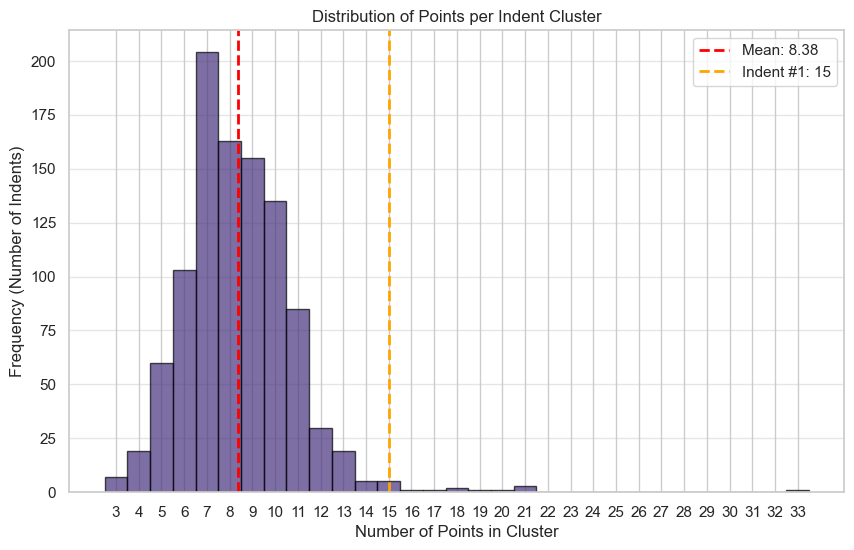

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# CLUSTER SIZE INSPECTION
# ==========================================

# 1. Count points in each valid cluster (ignoring noise -1)
# We assume 'indent_points_df_filtered' has the 'cluster_label' column from DBSCAN
valid_clusters = indent_points_df_filtered[indent_points_df_filtered['cluster_label'] != -1]
cluster_counts = valid_clusters['cluster_label'].value_counts()

# 2. Calculate Statistics
print("--- Cluster Size Statistics ---")
print(cluster_counts.describe())

# 3. Check Indent #1 specifically
# We need to know which cluster maps to Indent #1. 
# Based on our logic, it's the 1st cluster in the 'final_map_df'.
indent_1_cluster_label = final_map_df.iloc[0]['cluster_label']
points_in_indent_1 = cluster_counts[indent_1_cluster_label]

print(f"\nIndent #1 (Cluster ID {indent_1_cluster_label}) has {points_in_indent_1} points.")

# 4. Plot Histogram
plt.figure(figsize=(10, 6))
plt.hist(cluster_counts, bins=range(min(cluster_counts), max(cluster_counts) + 2), 
         edgecolor='black', align='left', alpha=0.7)
plt.axvline(cluster_counts.mean(), color='red', linestyle='dashed', linewidth=2, label=f'Mean: {cluster_counts.mean():.2f}')
plt.axvline(points_in_indent_1, color='orange', linestyle='dashed', linewidth=2, label=f'Indent #1: {points_in_indent_1}')

plt.xlabel('Number of Points in Cluster')
plt.ylabel('Frequency (Number of Indents)')
plt.title('Distribution of Points per Indent Cluster')
plt.legend()
plt.grid(axis='y', alpha=0.5)
plt.xticks(range(min(cluster_counts), max(cluster_counts) + 1))
plt.show()

In [14]:
import json
import numpy as np

output_filename = "final_indentation_dataset.json"

# --- Fix: Convert keys to strings ---
# This creates a new dictionary where keys are '1', '2' instead of numpy.int64(1), etc.
clean_dataset = {str(key): value for key, value in final_dataset_dict.items()}

print(f"Saving dataset to {output_filename}...")

# Use the NumpyEncoder for the *values* inside the dictionary
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        elif isinstance(obj, np.floating):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NumpyEncoder, self).default(obj)

with open(output_filename, 'w') as f:
    json.dump(clean_dataset, f, cls=NumpyEncoder) # No indent to keep file size smaller

print("Success! Dataset saved correctly.")

Saving dataset to final_indentation_dataset.json...
Success! Dataset saved correctly.
